In [ ]:
import pandas as pd
from google.colab import drive

# Mount your Google Drive
# When you run this, a pop-up will ask for permission to access your files.
drive.mount('/content/drive')

# Define the path to your specific file
# Based on your image: My Drive > Colab Notebooks> datasets > isoc_ci_in_h_linear_2_0.csv
file_path = '/content/drive/MyDrive/Colab Notebooks/datasets/isoc_ci_in_h_linear_2_0.csv'

# Load the dataset into a pandas DataFrame
df = pd.read_csv(file_path)

# see the dataset details
print('shape:',df.shape)
print('columns',df.columns.tolist())
df.head()

Mounted at /content/drive
shape: (11918, 19)
columns ['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Time frequency', 'unit', 'Unit of measure', 'hhtyp', 'Type of household', 'geo', 'Geopolitical entity (reporting)', 'TIME_PERIOD', 'Time', 'OBS_VALUE', 'Observation value', 'OBS_FLAG', 'Observation status (Flag) V2 structure', 'CONF_STATUS', 'Confidentiality status (flag)']


,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,unit,Unit of measure,hhtyp,Type of household,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:ISOC_CI_IN_H(1.0),Households - level of internet access,A,Annual,PC_HH,Percentage of households,A1,Single person,AL,Albania,2018,NaN,56.73,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:ISOC_CI_IN_H(1.0),Households - level of internet access,A,Annual,PC_HH,Percentage of households,A1,Single person,AL,Albania,2020,NaN,58.56,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:ISOC_CI_IN_H(1.0),Households - level of internet access,A,Annual,PC_HH,Percentage of households,A1,Single person,AL,Albania,2021,NaN,70.76,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:ISOC_CI_IN_H(1.0),Households - level of internet access,A,Annual,PC_HH,Percentage of households,A1,Single person,AL,Albania,2022,NaN,89.59,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:ISOC_CI_IN_H(1.0),Households - level of internet access,A,Annual,PC_HH,Percentage of households,A1,Single person,AL,Albania,2023,NaN,83.19,NaN,NaN,NaN,NaN,NaN


In [ ]:
keep_cols = [
    "freq",
    "unit",
    "hhtyp",
    "Type of household",
    "geo",
    "Geopolitical entity (reporting)",
    "TIME_PERIOD",
    "OBS_VALUE",
    "OBS_FLAG"
]

df = df[keep_cols].copy()
df.head()


,freq,unit,hhtyp,Type of household,geo,Geopolitical entity (reporting),TIME_PERIOD,OBS_VALUE,OBS_FLAG
0,A,PC_HH,A1,Single person,AL,Albania,2018,56.73,NaN
1,A,PC_HH,A1,Single person,AL,Albania,2020,58.56,NaN
2,A,PC_HH,A1,Single person,AL,Albania,2021,70.76,NaN
3,A,PC_HH,A1,Single person,AL,Albania,2022,89.59,NaN
4,A,PC_HH,A1,Single person,AL,Albania,2023,83.19,NaN


In [ ]:
df = df.rename(columns={
    "Type of household": "hhtyp_label",
    "Geopolitical entity (reporting)": "country",
    "TIME_PERIOD": "year",
    "OBS_VALUE": "value",
    "OBS_FLAG": "obs_flag"
})

df.head()


,freq,unit,hhtyp,hhtyp_label,geo,country,year,value,obs_flag
0,A,PC_HH,A1,Single person,AL,Albania,2018,56.73,NaN
1,A,PC_HH,A1,Single person,AL,Albania,2020,58.56,NaN
2,A,PC_HH,A1,Single person,AL,Albania,2021,70.76,NaN
3,A,PC_HH,A1,Single person,AL,Albania,2022,89.59,NaN
4,A,PC_HH,A1,Single person,AL,Albania,2023,83.19,NaN


In [ ]:
# Convert to numeric
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["value"] = pd.to_numeric(df["value"], errors="coerce")

# Filter: annual data + percentage of households
df_clean = df[
    (df["freq"] == "A") &
    (df["unit"] == "PC_HH")
].copy()

# Drop missing essentials
df_clean = df_clean.dropna(subset=["year", "geo", "value"])

print("Cleaned shape:", df_clean.shape)
df_clean.head()


Cleaned shape: (11757, 9)


,freq,unit,hhtyp,hhtyp_label,geo,country,year,value,obs_flag
0,A,PC_HH,A1,Single person,AL,Albania,2018,56.73,NaN
1,A,PC_HH,A1,Single person,AL,Albania,2020,58.56,NaN
2,A,PC_HH,A1,Single person,AL,Albania,2021,70.76,NaN
3,A,PC_HH,A1,Single person,AL,Albania,2022,89.59,NaN
4,A,PC_HH,A1,Single person,AL,Albania,2023,83.19,NaN


In [ ]:
# find the rows with one person households
df_single = df_clean[df_clean["hhtyp"] == "A1"].copy()

print("Single-person rows:", df_single.shape)
df_single[["hhtyp", "hhtyp_label"]].drop_duplicates()


Single-person rows: (820, 9)


,hhtyp,hhtyp_label
0,A1,Single person


In [ ]:
# Countries to include
countries = ["IT", "EU27_2020", "DE", "FR"]

df_viz1 = df_single[df_single["geo"].isin(countries)].copy()

df_viz1[["geo", "country"]].drop_duplicates()


,geo,country
128,DE,Germany
308,EU27_2020,European Union - 27 countries (from 2020)
364,FR,France
466,IT,Italy


In [ ]:
df_viz1.groupby("country")["year"].agg(["min", "max"])


,min,max
country,,
European Union - 27 countries (from 2020),2007,2025
France,2002,2025
Germany,2002,2025
Italy,2002,2025


In [ ]:
viz1_table = (
    df_viz1
    .pivot_table(
        index="year",
        columns="country",
        values="value"
    )
    .reset_index()
    .sort_values("year")
)

viz1_table.head(10)


country,year,European Union - 27 countries (from 2020),France,Germany,Italy
0,2002,NaN,10.18,33.33,11.02
1,2003,NaN,13.66,36.56,22.36
2,2004,NaN,20.28,44.32,21.06
3,2005,NaN,NaN,45.93,20.85
4,2006,NaN,24.97,48.04,20.95
5,2007,39.29,38.75,54.51,24.45
6,2008,43.28,43.74,58.16,27.67
7,2009,49.57,51.36,65.40,34.13
8,2010,54.23,57.69,70.72,38.94
9,2011,56.01,55.74,71.68,41.91


In [ ]:
viz1_table.to_csv("viz1_single_person_time_series.csv", index=False)

print("Saved file: viz1_single_person_time_series.csv")


Saved file: viz1_single_person_time_series.csv


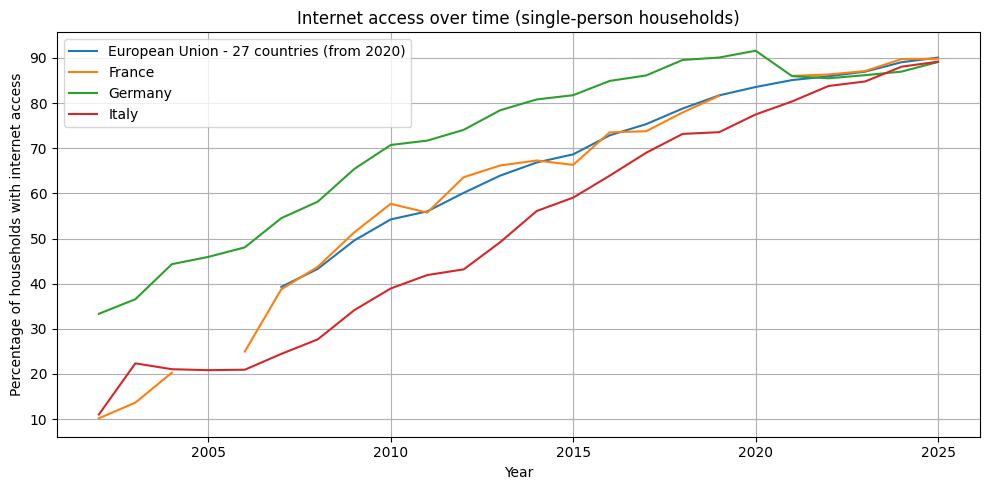

In [ ]:
# this is the first visualization
# Vis 1 → trends over time
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for col in viz1_table.columns:
    if col != "year":
        plt.plot(viz1_table["year"], viz1_table[col], label=col)

plt.xlabel("Year")
plt.ylabel("Percentage of households with internet access")
plt.title("Internet access over time (single-person households)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# finding out the most recent year
latest_year = int(df_single["year"].max())

In [ ]:
# getting the data of the most recent year
df_latest = df_single[df_single["year"] == latest_year].copy()

print("Rows in latest year:", df_latest.shape)
df_latest.head()


Rows in latest year: (36, 9)


,freq,unit,hhtyp,hhtyp_label,geo,country,year,value,obs_flag
29,A,PC_HH,A1,Single person,AT,Austria,2025,91.59,NaN
36,A,PC_HH,A1,Single person,BA,Bosnia and Herzegovina,2025,65.79,NaN
57,A,PC_HH,A1,Single person,BE,Belgium,2025,84.32,NaN
77,A,PC_HH,A1,Single person,BG,Bulgaria,2025,83.35,NaN
83,A,PC_HH,A1,Single person,CH,Switzerland,2025,97.40,NaN


In [ ]:
# Some countries may have duplicate rows (rare but possible).
# We safely aggregate using the mean.
viz2_table = (
    df_latest
    .groupby(["geo", "country"], as_index=False)["value"]
    .mean()
)

viz2_table = viz2_table.sort_values("value", ascending=False)
viz2_table.head()


,geo,country,value
26,NL,Netherlands,99.37
27,NO,Norway,98.58
21,LU,Luxembourg,98.42
4,CH,Switzerland,97.40
14,FI,Finland,96.31


In [ ]:
viz2_table.to_csv(
    f"viz2_single_person_country_comparison_{latest_year}.csv",
    index=False
)

print(f"Saved file: viz2_single_person_country_comparison_{latest_year}.csv")


Saved file: viz2_single_person_country_comparison_2025.csv


/tmp/ipython-input-2336777008.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


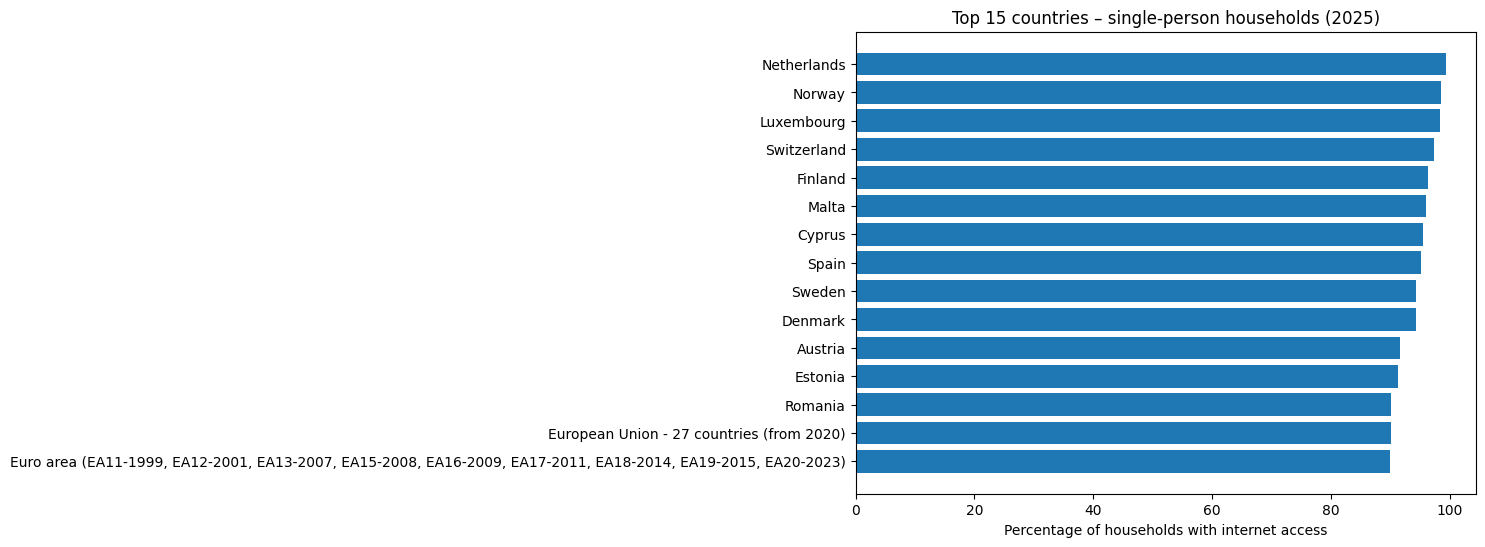

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

top15 = viz2_table.head(15)
plt.barh(top15["country"], top15["value"])
plt.xlabel("Percentage of households with internet access")
plt.title(f"Top 15 countries – single-person households ({latest_year})")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


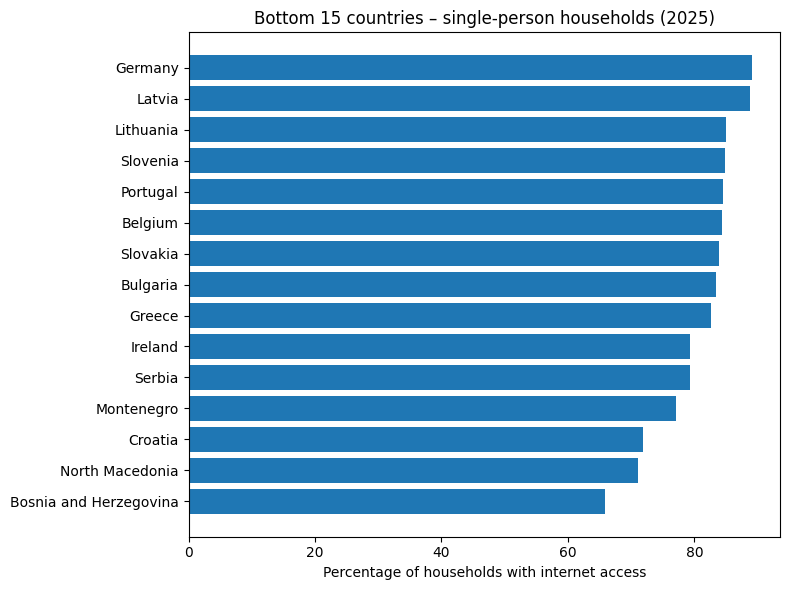

In [ ]:
bottom15 = viz2_table.tail(15)

plt.figure(figsize=(8, 6))
plt.barh(bottom15["country"], bottom15["value"])
plt.xlabel("Percentage of households with internet access")
plt.title(f"Bottom 15 countries – single-person households ({latest_year})")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
